In [11]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

In [22]:
class BMIState(TypedDict):
    weight_kg: float
    height_m: float
    bmi: float = 0.0
    category: str

In [21]:
def calculate_bmi(state: BMIState)-> BMIState:
    state['bmi'] = state['weight_kg'] / (state['height_m'] ** 2)
    return state

def categorize_bmi(state: BMIState) -> BMIState:
    bmi = state['bmi']
    if bmi < 18.5:
        state['category'] = 'Underweight'
    elif 18.5 <= bmi < 24.9:
        state['category'] = 'Normal weight'
    elif 25 <= bmi < 29.9:
        state['category'] = 'Overweight'
    else:
        state['category'] = 'Obesity'
    return state

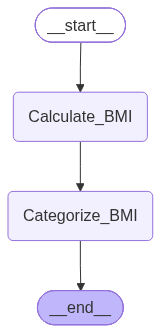

In [25]:
#defining Graph
graph = StateGraph(BMIState)

#Defining Nodes
graph.add_node("Calculate_BMI",calculate_bmi)
graph.add_node("Categorize_BMI",categorize_bmi)
#Defining Edges
graph.add_edge(START, "Calculate_BMI")
graph.add_edge("Calculate_BMI", "Categorize_BMI")
graph.add_edge("Categorize_BMI", END)
#Compiling Graph
workflow = graph.compile()

workflow

In [24]:
#Execute graph
initial_state = {"weight_kg": 70.0, "height_m": 1.75}
final_output = workflow.invoke(initial_state)
print(final_output) 

{'weight_kg': 70.0, 'height_m': 1.75, 'bmi': 22.857142857142858, 'category': 'Normal weight'}
